# 2. Measure raster objects


Create polygons once, then add spectral summaries, an index, shape, texture, and
pixel-validity measurements. This notebook also works independently with polygons
you have already created or drawn in a GIS.


This notebook runs independently and creates its own small, synthetic four-band
GeoTIFF. It needs no data downloads. Use the repository checkout and install
`python -m pip install -e ".[notebooks]"` from its root, then launch `jupyter lab`.
See the [notebook setup guide](https://obia.sefa.ai/examples/) for details.

Run the cells from top to bottom. Files go into this notebook's subdirectory of
`example_outputs/`; rerunning replaces those example files. All OBIA band selections
use **zero-based numeric indices** into the loaded raster.

[Download this notebook](02_raster_features.ipynb)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import from_origin

from obia.handlers.geotif import open_geotiff
import json

from obia.features import TextureConfig, extract_features
from obia.segmentation import create_segments

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "02_raster_features"
output_dir.mkdir(parents=True, exist_ok=True)

## Make and load a tiny raster

The scene contains three invented surface types, with different values in bands
0–3 and different amounts of variation. The grid is 96 × 128 pixels at 2 m per
pixel in a projected CRS. These coordinates are only for demonstrating geospatial
operations; the scene is not an observation of a real location.

Replace this cell with `image = open_geotiff("your_image.tif")` for your own data.
The loader reads all file bands here. Its optional `bands=` argument follows
Rasterio's **one-based** file numbering; subsequent OBIA selections are zero-based.

In [2]:
rng = np.random.default_rng(42)
rows, cols = np.indices((96, 128))
reference = np.zeros(rows.shape, dtype=np.uint8)
reference[rows < 46] = 1
reference[((rows - 58) / 25) ** 2 + ((cols - 83) / 31) ** 2 < 1] = 2

# Each row contains values for bands [0, 1, 2, 3] of one surface type.
spectra = np.array([[0.48, 0.36, 0.22, 0.32],
                    [0.12, 0.38, 0.15, 0.68],
                    [0.08, 0.18, 0.30, 0.04]])
noise = np.array([0.015, 0.045, 0.006])[reference, None]
values = np.clip(spectra[reference] + rng.normal(size=(96, 128, 4)) * noise, 0, 1)
transform = from_origin(500_000, 2_200_000, 2, 2)
raster_path = output_dir / "sample.tif"
with rasterio.open(raster_path, "w", driver="GTiff", height=96, width=128,
                   count=4, dtype="float32", crs="EPSG:32604", transform=transform) as dst:
    dst.write(values.astype("float32").transpose(2, 0, 1))

image = open_geotiff(raster_path)
image.rasterio_obj.close()  # The loaded values, masks, CRS, and transform remain available.
print(f"Loaded array: {image.img_data.shape}; CRS: {image.crs}")

Loaded array: (96, 128, 4); CRS: EPSG:32604


## Create or load polygons

`create_segments()` returns polygons without calculating features. For existing
objects, replace this cell with
`polygons = gpd.read_file("segments.gpkg").to_crs(image.crs)`.

In [3]:
polygons = create_segments(
    image, segmentation_bands=[0, 1, 2, 3], method="slic",
    n_segments=100, compactness=0.2, sigma=0.6, convert2lab=False,
)
print(f"Starting with {len(polygons)} polygons")

Starting with 100 polygons


## Choose measurements

We summarize each band, calculate `(b3 - b0) / (b3 + b0)` for each pixel before
summarizing it, and measure shape in projected map units. Numeric band tuples
are explicit: the library does not infer a sensor's band order.

Texture uses band 0, a fixed range of 0–1 for this synthetic raster, and distances
of 1 and 2 pixels. Choose bounds appropriate to your own calibrated data. Local
entropy uses a radius of 2 pixels. Empty samples or objects with no valid texture
pairs receive missing values, rather than fabricated zeros.

In [4]:
objects = extract_features(
    polygons, image, bands=[0, 1, 2, 3],
    spectral=("mean", "std", "median", "iqr", "valid_count", "valid_fraction"),
    percentiles=(10, 90),
    indices={"normalized_difference": (3, 0)},
    shape=("area", "perimeter", "circularity", "elongation"),
    texture=TextureConfig(
        bands=(0,), features=("contrast", "homogeneity"), distances=(1, 2),
        levels=16, value_range=(0, 1), entropy_radii=(2,),
    ),
)
preview_columns = [
    "segment_id", "b0_median", "b3_p90", "index_normalized_difference_b3_b0_mean",
    "shape_area", "b0_glcm_contrast_d2", "b0_local_entropy_r2_mean",
]
objects[preview_columns].head()

,segment_id,b0_median,b3_p90,index_normalized_difference_b3_b0_mean,shape_area,b0_glcm_contrast_d2,b0_local_entropy_r2_mean
0,1,0.119598,0.742824,0.712829,484.0,0.917449,1.360229
1,3,0.117729,0.739890,0.705847,460.0,1.086947,1.376667
2,7,0.117240,0.737814,0.715783,476.0,1.271489,1.459216
3,2,0.125251,0.736197,0.686939,508.0,1.160574,1.348305
4,5,0.120461,0.736670,0.698467,500.0,1.248210,1.466366


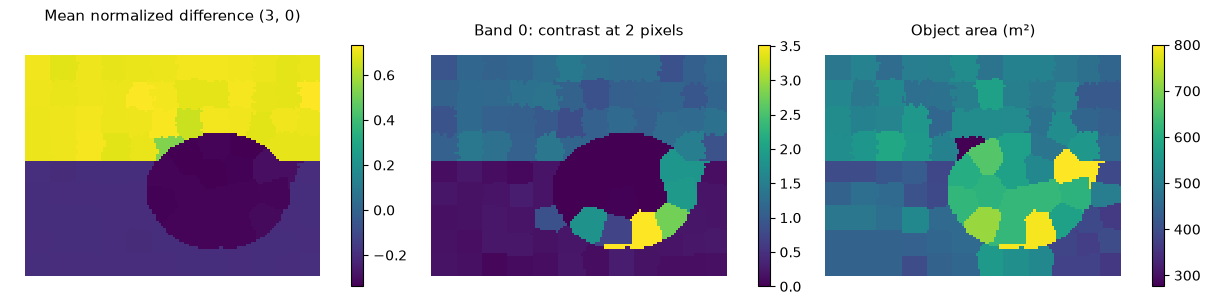

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for ax, column, title in zip(
    axes,
    ["index_normalized_difference_b3_b0_mean", "b0_glcm_contrast_d2", "shape_area"],
    ["Mean normalized difference (3, 0)", "Band 0: contrast at 2 pixels", "Object area (m²)"],
):
    objects.plot(column=column, ax=ax, legend=True, cmap="viridis",
                 legend_kwds={"shrink": 0.65}, missing_kwds={"color": "lightgrey"})
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## Inspect missing data and a quality mask

File NoData masks are honored automatically. An additional boolean mask can
exclude cloud or shadow pixels: `False` means excluded. Here we mask a rectangle
solely to demonstrate valid counts and fractions. The mask changes sampled pixels,
not the polygon boundaries or their areas.

`quality` below is a separate quality table; `objects` retains the complete-scene
features. In a real masked workflow, pass the same mask when calculating all
spectral, index, and texture features that should exclude those pixels.

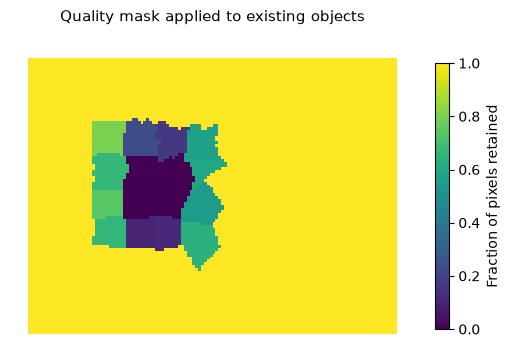

Objects affected by the mask: 16
Features with missing measurements: {}


In [6]:
rows, cols = np.indices(image.img_data.shape[:2])
valid_pixels = ~((rows >= 25) & (rows < 65) & (cols >= 30) & (cols < 60))
quality = extract_features(
    polygons, image, bands=[0], spectral=("valid_count", "valid_fraction"),
    percentiles=(), mask=valid_pixels,
)
fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
quality.plot(column="b0_valid_fraction", ax=ax, cmap="viridis", vmin=0, vmax=1,
             legend=True, legend_kwds={"label": "Fraction of pixels retained", "shrink": 0.8})
ax.set_title("Quality mask applied to existing objects")
ax.set_axis_off()
plt.show()

missing = objects.drop(columns="geometry").isna().sum()
print(f"Objects affected by the mask: {(quality.b0_valid_fraction < 1).sum()}")
print("Features with missing measurements:", missing[missing > 0].to_dict())

## Save features and their settings

GeoPackage stores the geometry and feature columns. The extraction configuration
in `objects.attrs` is in-memory metadata, so we save it separately as JSON.

In [7]:
objects.to_file(output_dir / "object_features.gpkg", layer="objects", driver="GPKG")
(output_dir / "feature_settings.json").write_text(
    json.dumps(objects.attrs["obia_features"], indent=2), encoding="utf-8",
)
saved_objects = gpd.read_file(output_dir / "object_features.gpkg", layer="objects")
assert set(preview_columns).issubset(saved_objects.columns)
print(f"Saved {len(saved_objects)} objects and their feature settings to {output_dir}")

Saved 100 objects and their feature settings to example_outputs/02_raster_features


Try changing texture distances or entropy radii, then rerun feature extraction
without repeating segmentation. Adding every possible feature is not necessarily
helpful: keep measurements that have a useful relationship to your classes.

Continue with [object classification](https://obia.sefa.ai/examples/03_classification/). The
[raster feature guide](https://obia.sefa.ai/usage/raster-features/) lists definitions and units.